<a href="https://colab.research.google.com/github/AkhilanairK-healthcare/akhila-hospital-readmission-quality/blob/main/notebooks/02_exploratory_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
BASE = '/content/drive/MyDrive/Akhila-portfolio/Project2-data/'
fact = pd.read_csv(BASE + 'fact_readmissions.csv')
hosp = pd.read_csv(BASE + 'dim_hospital.csv')
print(fact.shape, hosp.shape)

(18330, 14) (5435, 6)


In [3]:
print(fact.groupby('condition')['excess_readmission_ratio'].mean().round(4))
print((fact.groupby('condition')['above_benchmark'].mean() * 100).round(1))

condition
CABG (Bypass Surgery)    1.0018
COPD                     1.0011
Heart Attack (AMI)       1.0018
Heart Failure            1.0014
Hip/Knee Replacement     1.0040
Pneumonia                1.0015
Name: excess_readmission_ratio, dtype: float64
condition
CABG (Bypass Surgery)    49.9
COPD                     47.2
Heart Attack (AMI)       49.7
Heart Failure            48.9
Hip/Knee Replacement     47.9
Pneumonia                46.8
Name: above_benchmark, dtype: float64


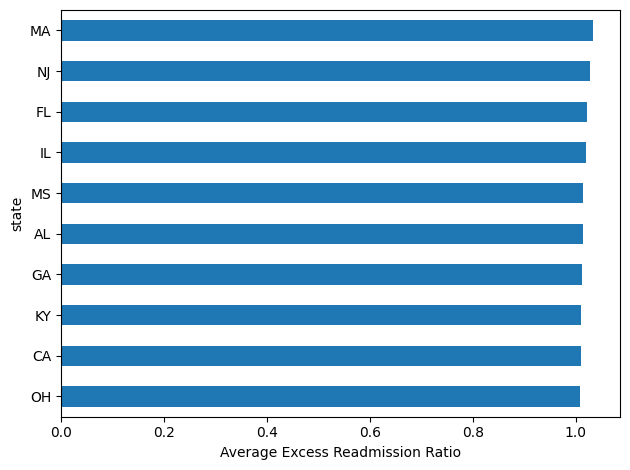

In [4]:
s = fact.groupby('state')['excess_readmission_ratio'].agg(['mean','count'])
s[s['count'] >= 100]['mean'].sort_values().tail(10).plot(kind='barh')
plt.xlabel('Average Excess Readmission Ratio'); plt.tight_layout(); plt.show()


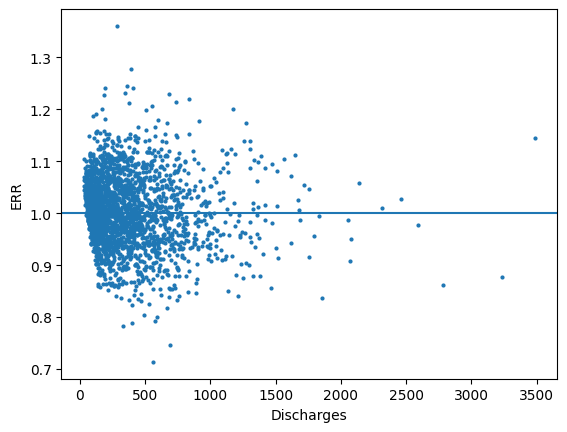

In [5]:
hf = fact[fact['condition'] == 'Heart Failure']
plt.scatter(hf['number_of_discharges'], hf['excess_readmission_ratio'], s=4)
plt.axhline(1.0); plt.xlabel('Discharges'); plt.ylabel('ERR'); plt.show()